In [1]:
# Timer for notebook
import time
_start_time = time.perf_counter()

# Put imports here
import numpy as np
from scipy import stats, special, integrate, fft
import matplotlib.pyplot as plt
import mp3lib as ml

SEED = 690403480 # drawn 2026-11-23, do not change
rng = np.random.default_rng(SEED)
rng_1, rng_2, rng_3, rng_4, rng_5, rng_6, rng_7, rng_8, rng_A, rng_B = rng.spawn(10)

magnitude = 6
n = np.zeros(magnitude + 1, dtype=int)
for i in range(magnitude + 1):
    n[i] = 10 ** i

## Step 1

## Step 2

## Step 3

## Step 4

## Step 5

## Step 6

## Step 7

## The Conditional Gaussian

### Part 1:

With mean zero and Σ = [[4, 2], [2, 4]]: det Σ = 12 and Σ⁻¹ = (1/12)[[4, -2], [-2, 4]].

The exponent of the joint density is
$$-\tfrac12 \mathbf v^T\Sigma^{-1}\mathbf v = -\tfrac16\,(x^2 - xy + y^2).$$

Complete the square in y:
$$x^2 - xy + y^2 = \left(y - \tfrac{x}{2}\right)^2 + \tfrac34 x^2 .$$

So the joint density factors into a piece with only x and a piece with y:
$$f_{XY}(x,y) = \underbrace{\frac{1}{\sqrt{2\pi\cdot 4}}e^{-x^2/8}}_{f_X(x),\ X\sim N(0,4)} \cdot \frac{1}{\sqrt{2\pi\cdot 3}}\exp\!\left(-\frac{(y-x/2)^2}{2\cdot 3}\right).$$

Dividing by $f_X(x)$ gives
$$Y \mid X=x \sim N(0.5\,x,\ 3).$$
It is Gaussian, the mean is linear in x, and the variance does not depend on x.


### Part 2: 
For a partitioned Gaussian vector with blocks a and b:
$$\mu_{a|b} = \mu_a + \Sigma_{ab}\Sigma_{bb}^{-1}(x_b-\mu_b), \qquad
\Sigma_{a|b} = \Sigma_{aa} - \Sigma_{ab}\Sigma_{bb}^{-1}\Sigma_{ba}.$$

Here a = Y, b = X, so $\Sigma_{aa}=4$, $\Sigma_{ab}=2$, $\Sigma_{bb}=4$:
$$\mu_{Y|X} = \tfrac{2}{4}x = 0.5x, \qquad \sigma^2_{Y|X} = 4 - \tfrac{2\cdot 2}{4} = 3.$$
This matches Part 1.

Binned slope = 0.4998 +/- 0.0009  (analytic 0.5, 0.26 SE away)
Raw slope    = 0.5013 +/- 0.0009
Bins used: 40
Conditional variance: mean of bins = 3.0081, min = 2.941, max = 3.171  (analytic 3)


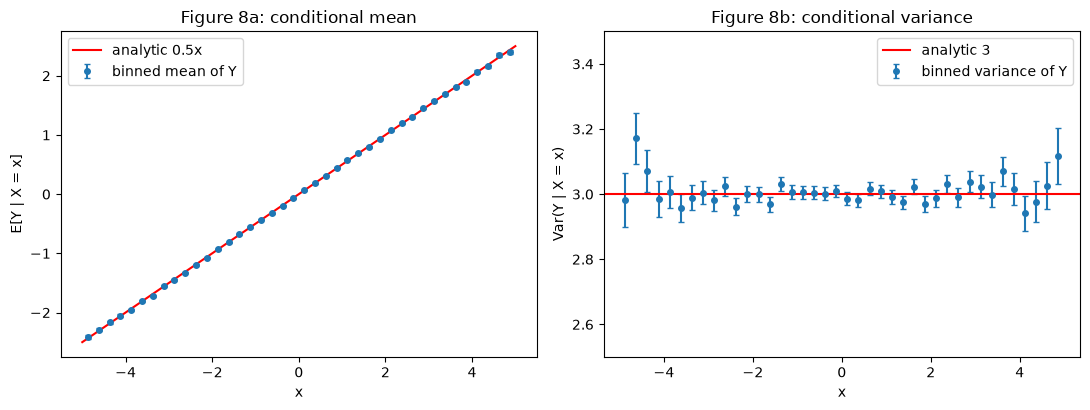

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

Sigma = np.array([[4.0, 2.0], [2.0, 4.0]])
N = 10**6
samples = rng_7.multivariate_normal([0, 0], Sigma, size=N)
x, y = samples[:, 0], samples[:, 1]

# Parts 3 and 4: bin by x, then get the mean and variance of y in each bin
edges = np.linspace(-5, 5, 41)           # 40 bins, width 0.25
bin_x, bin_mean, bin_var, se_mean, se_var = [], [], [], [], []

for k in range(40):
    in_bin = (x >= edges[k]) & (x < edges[k + 1])
    n = in_bin.sum()
    if n < 200:                           # skip bins with too few samples
        continue
    yb = y[in_bin]
    v = yb.var(ddof=1)
    bin_x.append(x[in_bin].mean())        # use the average x in the bin, not the bin center
    bin_mean.append(yb.mean())
    bin_var.append(v)
    se_mean.append(np.sqrt(v / n))        # standard error of a mean
    se_var.append(v * np.sqrt(2 / (n - 1)))   # standard error of a variance (Gaussian data)

bin_x, bin_mean, bin_var = np.array(bin_x), np.array(bin_mean), np.array(bin_var)
se_mean, se_var = np.array(se_mean), np.array(se_var)

# slope of the binned means, plus a check using all the raw samples
fit_bins = stats.linregress(bin_x, bin_mean)
fit_raw = stats.linregress(x, y)
z_slope = (fit_bins.slope - 0.5) / fit_bins.stderr

print(f"Binned slope = {fit_bins.slope:.4f} +/- {fit_bins.stderr:.4f}  (analytic 0.5, {abs(z_slope):.2f} SE away)")
print(f"Raw slope    = {fit_raw.slope:.4f} +/- {fit_raw.stderr:.4f}")
print(f"Bins used: {len(bin_x)}")
print(f"Conditional variance: mean of bins = {bin_var.mean():.4f}, "
      f"min = {bin_var.min():.3f}, max = {bin_var.max():.3f}  (analytic 3)")

# Figure 8
xx = np.linspace(-5, 5, 100)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

ax[0].errorbar(bin_x, bin_mean, yerr=se_mean, fmt="o", ms=4, capsize=2, label="binned mean of Y")
ax[0].plot(xx, 0.5 * xx, "r-", label="analytic 0.5x")
ax[0].set_xlabel("x"); ax[0].set_ylabel("E[Y | X = x]")
ax[0].set_title("Figure 8a: conditional mean"); ax[0].legend()

ax[1].errorbar(bin_x, bin_var, yerr=se_var, fmt="o", ms=4, capsize=2, label="binned variance of Y")
ax[1].axhline(3, color="r", label="analytic 3")
ax[1].set_ylim(2.5, 3.5)
ax[1].set_xlabel("x"); ax[1].set_ylabel("Var(Y | X = x)")
ax[1].set_title("Figure 8b: conditional variance"); ax[1].legend()
plt.tight_layout(); plt.show()

### Part 5: 

The estimator with the smallest mean squared error among *all* functions of $X$, linear or not, is the
conditional mean $E[Y\mid X]$. For jointly Gaussian data, Part 1 shows this conditional mean is
$0.5\,x$, which is already a linear function of $x$. So the best linear estimator and the best possible
estimator coincide, and no nonlinear function can beat the linear one. For non-Gaussian data this fails. In
Step 2, $Y=X^2$ is perfectly predictable from $X$ by a nonlinear function while the best linear
estimator is useless, because the correlation is zero. Because the conditional variance is also constant, the
achieved error is the same for every observed $x$. It equals $\Sigma_{a|b}=\Sigma_{aa}-\Sigma_{ab}\Sigma_{bb}^{-1}\Sigma_{ba}$,
which is exactly the MMSE expression $\sigma_s^2-\Sigma_{sx}^T\Sigma_{xx}^{-1}\Sigma_{sx}$ we use in Step 8.

## Step 8

## Bonus A

## Bonus B

In [3]:
_end_time = time.perf_counter()
print(f"Total Notebook Runtime: {_end_time - _start_time:.3f} seconds")

Total Notebook Runtime: 3.404 seconds
